# Campanha PQC/O-RAN — Análise e Gráficos

Carrega todos os `.jsonl` de `results/` (saída do `run_experiment.py`) e gera os gráficos principais: latência (CDF + percentis), throughput, timing de rekey PQC, isolamento por fatia, CPU/memória, e a correlação rotação↔latência.

Rode as células em ordem. Se trocar a campanha, só precisa rodar de novo a partir da célula de carregamento.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

RESULTS_DIR = Path("results")

# paleta categórica validada (ordem fixa — nunca reciclar hue por rank),
# ver skill de dataviz / references/palette.md
SCENARIO_ORDER = [
    "cenario0_baseline_nativo",
    "cenario1_pqc_estatico",
    "cenario2_diferenciado_edf",
    "cenario3_risk_aware",
    "cenario4_contencao",
]
SCENARIO_LABELS = {
    "cenario0_baseline_nativo": "0 — Baseline",
    "cenario1_pqc_estatico": "1 — PQC estático",
    "cenario2_diferenciado_edf": "2 — Diferenciado (EDF)",
    "cenario3_risk_aware": "3 — Risk-aware",
    "cenario4_contencao": "4 — Contenção",
}
SCENARIO_COLOR = {
    "cenario0_baseline_nativo": "#2a78d6",   # blue
    "cenario1_pqc_estatico": "#eb6834",      # orange
    "cenario2_diferenciado_edf": "#1baf7a",  # aqua
    "cenario3_risk_aware": "#eda100",        # yellow
    "cenario4_contencao": "#e87ba4",         # magenta
}
MARK_LABELS = {"0x10": "URLLC", "0x20": "eMBB", "0x30": "mIoT"}

INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRID = "#e1e0d9"
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "text.color": INK,
    "xtick.color": INK_SECONDARY,
    "ytick.color": INK_SECONDARY,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

In [2]:
def _scenario_from_run_id(run_id: str) -> str:
    # run_id = "<NAME>-<iteracao>-<hex>" — NAME pode ter "_" no meio, corta pelos 2 ultimos "-"
    parts = run_id.rsplit("-", 2)
    return parts[0] if len(parts) == 3 else run_id


def load_events(input_dir: Path) -> pd.DataFrame:
    records = []
    for path in sorted(input_dir.glob("*.jsonl")):
        with open(path) as f:
            for line in f:
                line = line.strip()
                if line:
                    records.append(json.loads(line))
    if not records:
        raise SystemExit(f"nenhum evento em {input_dir} — rode run_experiment.py primeiro")
    df = pd.json_normalize(records)
    df["scenario"] = df["run_id"].apply(_scenario_from_run_id)
    return df


def subset(df: pd.DataFrame, event: str, columns: list[str]) -> pd.DataFrame:
    ev = df[df["event"] == event]
    for col in columns:
        if col not in ev.columns:
            ev = ev.assign(**{col: pd.NA})
    return ev[columns].dropna(how="all", subset=[c for c in columns if c not in ("scenario", "run_id")])


def present_scenarios(df: pd.DataFrame) -> list[str]:
    have = set(df["scenario"].unique())
    return [s for s in SCENARIO_ORDER if s in have]


df = load_events(RESULTS_DIR)
scenarios = present_scenarios(df)
print(f"{len(df)} eventos carregados, {df['run_id'].nunique()} execuções, cenários: {scenarios}")

2770460 eventos carregados, 150 execuções, cenários: ['cenario0_baseline_nativo', 'cenario1_pqc_estatico', 'cenario2_diferenciado_edf', 'cenario3_risk_aware', 'cenario4_contencao']


## Latência (URLLC) — CDF e percentis

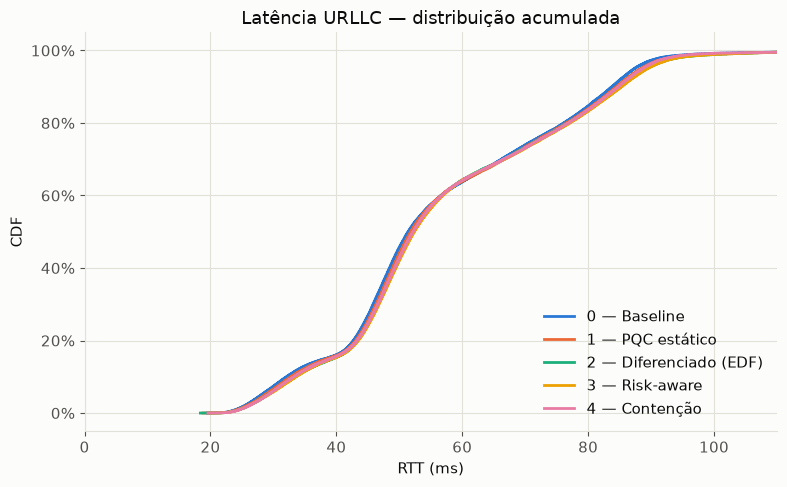

In [3]:
latency = subset(df, "latency_sample", ["scenario", "label", "rtt_ms"])
latency = latency[latency["label"] == "urllc"]
latency["rtt_ms"] = pd.to_numeric(latency["rtt_ms"])

fig, ax = plt.subplots(figsize=(8, 5))
for scen in scenarios:
    vals = np.sort(latency.loc[latency["scenario"] == scen, "rtt_ms"].to_numpy())
    if len(vals) == 0:
        continue
    y = np.arange(1, len(vals) + 1) / len(vals)
    ax.plot(vals, y, color=SCENARIO_COLOR[scen], linewidth=2, label=SCENARIO_LABELS[scen])

ax.set_xlim(0, np.percentile(latency["rtt_ms"], 99.5))
ax.set_xlabel("RTT (ms)")
ax.set_ylabel("CDF")
ax.set_title("Latência URLLC — distribuição acumulada", color=INK, fontsize=13)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig("report/notebook_latency_cdf.png", dpi=150)
plt.show()

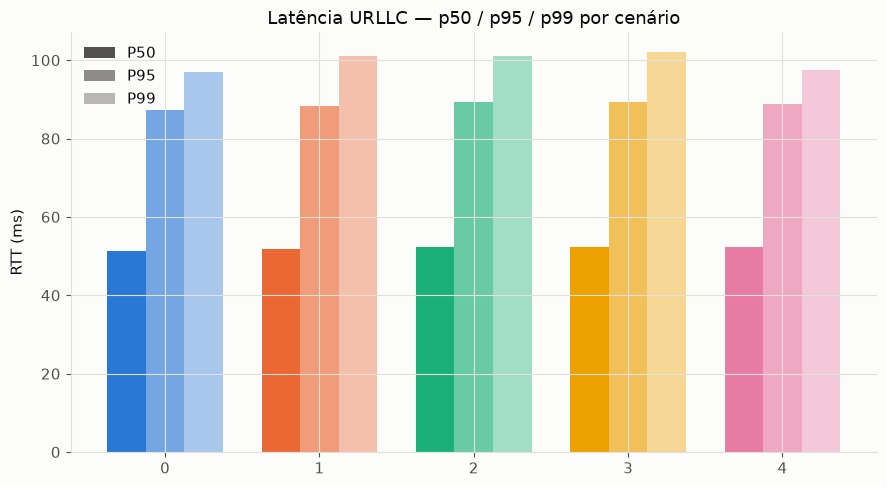

,p50,p95,p99
scenario,,,
cenario0_baseline_nativo,51.4,87.4,97.1
cenario1_pqc_estatico,51.8,88.4,101.0
cenario2_diferenciado_edf,52.3,89.2,101.0
cenario3_risk_aware,52.4,89.4,102.0
cenario4_contencao,52.2,88.7,97.4


In [4]:
pct = (
    latency.groupby("scenario")["rtt_ms"]
    .agg(p50=lambda s: s.quantile(0.50), p95=lambda s: s.quantile(0.95), p99=lambda s: s.quantile(0.99))
    .reindex(scenarios)
)

x = np.arange(len(scenarios))
width = 0.25
fig, ax = plt.subplots(figsize=(9, 5))
for i, pctl in enumerate(["p50", "p95", "p99"]):
    offset = (i - 1) * width
    bars = ax.bar(x + offset, pct[pctl], width, label=pctl.upper(),
                   color=[SCENARIO_COLOR[s] for s in scenarios], alpha=[1.0, 0.65, 0.4][i])
ax.set_xticks(x)
ax.set_xticklabels([SCENARIO_LABELS[s].split(" — ")[0] for s in scenarios])
ax.set_ylabel("RTT (ms)")
ax.set_title("Latência URLLC — p50 / p95 / p99 por cenário", color=INK, fontsize=13)
# legenda só precisa indicar o percentil (a cor/transparência já é o cenário no eixo X)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor=INK_SECONDARY, alpha=a, label=p) for p, a in zip(["P50", "P95", "P99"], [1.0, 0.65, 0.4])],
          frameon=False)
fig.tight_layout()
fig.savefig("report/notebook_latency_percentiles.png", dpi=150)
plt.show()
pct.round(1)

## Throughput (eMBB / mIoT)

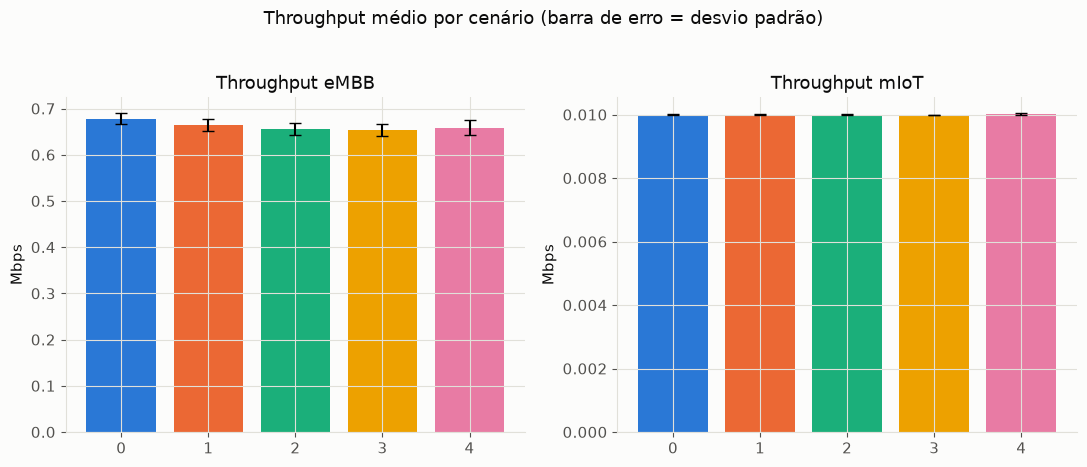

In [5]:
throughput = subset(df, "throughput_probe_summary", ["scenario", "label", "mbps"])
throughput["mbps"] = pd.to_numeric(throughput["mbps"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, label, title in zip(axes, ["embb", "miot"], ["eMBB", "mIoT"]):
    sub = throughput[throughput["label"] == label].groupby("scenario")["mbps"].agg(["mean", "std"]).reindex(scenarios)
    ax.bar(range(len(scenarios)), sub["mean"], yerr=sub["std"], capsize=4,
           color=[SCENARIO_COLOR[s] for s in scenarios])
    ax.set_xticks(range(len(scenarios)))
    ax.set_xticklabels([SCENARIO_LABELS[s].split(" — ")[0] for s in scenarios])
    ax.set_ylabel("Mbps")
    ax.set_title(f"Throughput {title}", color=INK, fontsize=13)
fig.suptitle("Throughput médio por cenário (barra de erro = desvio padrão)", color=INK, fontsize=13, y=1.03)
fig.tight_layout()
fig.savefig("report/notebook_throughput.png", dpi=150)
plt.show()

## Timing de rekey PQC (keygen + confirmação de SA)

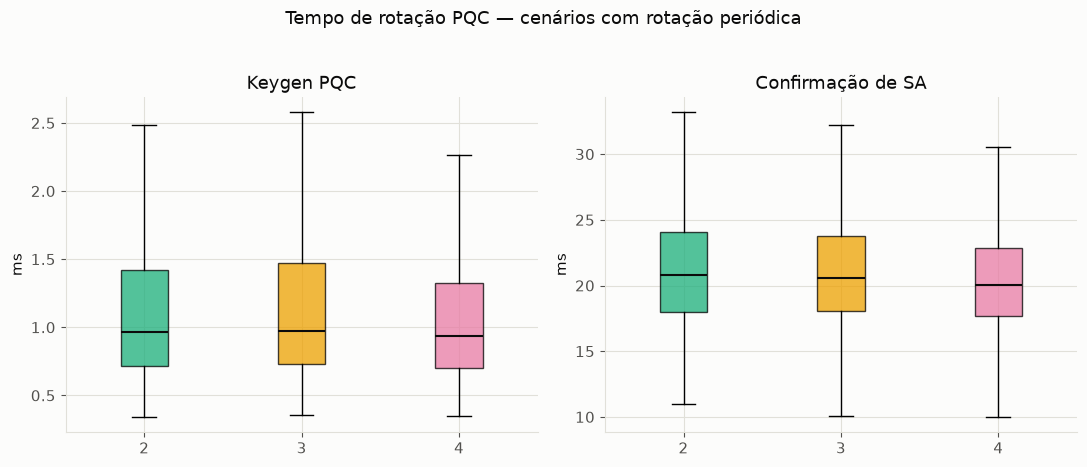

In [6]:
keygen = subset(df, "keygen_pqc_end", ["scenario", "duration_seconds"]).assign(stage="keygen_pqc")
spi = subset(df, "spi_confirmation_end", ["scenario", "duration_seconds"]).assign(stage="spi_confirmation")
rekey = pd.concat([keygen, spi], ignore_index=True)
rekey["duration_ms"] = pd.to_numeric(rekey["duration_seconds"]) * 1000
rotation_scenarios = [s for s in scenarios if s in rekey["scenario"].unique()]

if rotation_scenarios:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    for ax, stage, title in zip(axes, ["keygen_pqc", "spi_confirmation"], ["Keygen PQC", "Confirmação de SA"]):
        data = [rekey.loc[(rekey["scenario"] == s) & (rekey["stage"] == stage), "duration_ms"] for s in rotation_scenarios]
        bp = ax.boxplot(data, patch_artist=True, showfliers=False,
                         medianprops=dict(color=INK, linewidth=1.5))
        for patch, s in zip(bp["boxes"], rotation_scenarios):
            patch.set_facecolor(SCENARIO_COLOR[s])
            patch.set_alpha(0.75)
        ax.set_xticks(range(1, len(rotation_scenarios) + 1))
        ax.set_xticklabels([SCENARIO_LABELS[s].split(" — ")[0] for s in rotation_scenarios])
        ax.set_ylabel("ms")
        ax.set_title(title, color=INK, fontsize=13)
    fig.suptitle("Tempo de rotação PQC — cenários com rotação periódica", color=INK, fontsize=13, y=1.03)
    fig.tight_layout()
    fig.savefig("report/notebook_rekey_timing.png", dpi=150)
    plt.show()
else:
    print("nenhum cenário com rotação nesta coleta")

## Isolamento por fatia (classificação vs. SA real)

Compara o total de pacotes marcados por fatia (`iptables mangle`) contra o total que a SA daquela fatia efetivamente carregou. Tolerância de 3% (ver `analyze.py` pro histórico de como esse número foi calibrado).

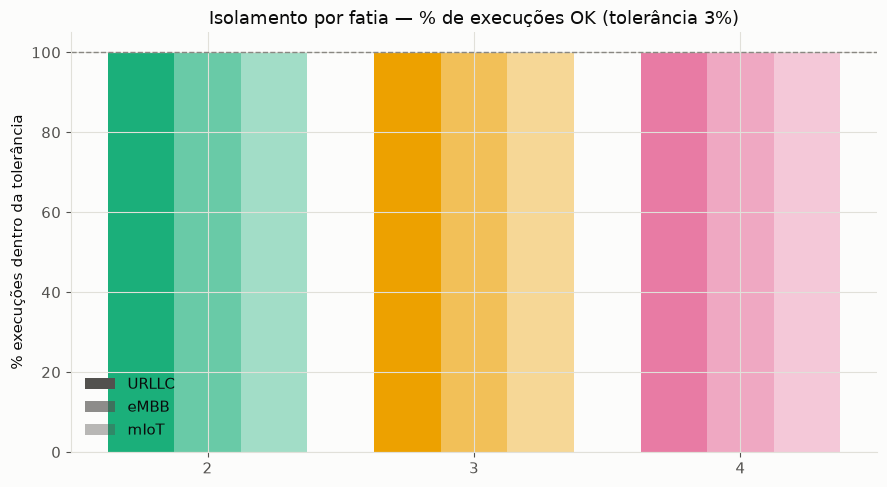

In [7]:
classification = subset(df, "classification_snapshot", ["scenario", "run_id", "mark", "packets"]).dropna(subset=["mark"])
xfrm = subset(df, "xfrm_snapshot", ["scenario", "run_id", "mark", "spi", "packets"]).dropna(subset=["mark"])

if not classification.empty and not xfrm.empty:
    cls_last = classification.groupby(["scenario", "run_id", "mark"])["packets"].max().rename("classified")
    per_spi_peak = xfrm.groupby(["scenario", "run_id", "mark", "spi"])["packets"].max()
    sa_total = per_spi_peak.groupby(["scenario", "run_id", "mark"]).sum().rename("sa_total")
    joined = pd.concat([cls_last, sa_total], axis=1).reset_index()
    diff = (joined["classified"] - joined["sa_total"]).abs()
    tolerance = (joined["classified"] * 0.03).clip(lower=2)
    joined["ok"] = diff <= tolerance

    summary = joined.groupby(["scenario", "mark"])["ok"].agg(["sum", "count"])
    summary["pct_ok"] = 100 * summary["sum"] / summary["count"]
    summary = summary.reindex(scenarios, level="scenario").dropna()

    marks = sorted(summary.index.get_level_values("mark").unique())
    scen_with_marks = [s for s in scenarios if s in summary.index.get_level_values("scenario")]
    x = np.arange(len(scen_with_marks))
    width = 0.25
    fig, ax = plt.subplots(figsize=(9, 5))
    for i, mark in enumerate(marks):
        vals = [summary.loc[(s, mark), "pct_ok"] if (s, mark) in summary.index else 0 for s in scen_with_marks]
        ax.bar(x + (i - 1) * width, vals, width, label=MARK_LABELS.get(mark, mark),
               color=[SCENARIO_COLOR[s] for s in scen_with_marks], alpha=[1.0, 0.65, 0.4][i])
    ax.axhline(100, color=INK_MUTED, linewidth=1, linestyle="--")
    ax.set_ylim(0, 105)
    ax.set_xticks(x)
    ax.set_xticklabels([SCENARIO_LABELS[s].split(" — ")[0] for s in scen_with_marks])
    ax.set_ylabel("% execuções dentro da tolerância")
    ax.set_title("Isolamento por fatia — % de execuções OK (tolerância 3%)", color=INK, fontsize=13)
    ax.legend(handles=[Patch(facecolor=INK_SECONDARY, alpha=a, label=MARK_LABELS.get(m, m)) for m, a in zip(marks, [1.0, 0.65, 0.4])],
              frameon=False)
    fig.tight_layout()
    fig.savefig("report/notebook_isolation.png", dpi=150)
    plt.show()
    summary.round(1)
else:
    print("sem amostras de classificação/xfrm suficientes (normal pra cenário 0/1, sem SA por fatia)")

## CPU e memória

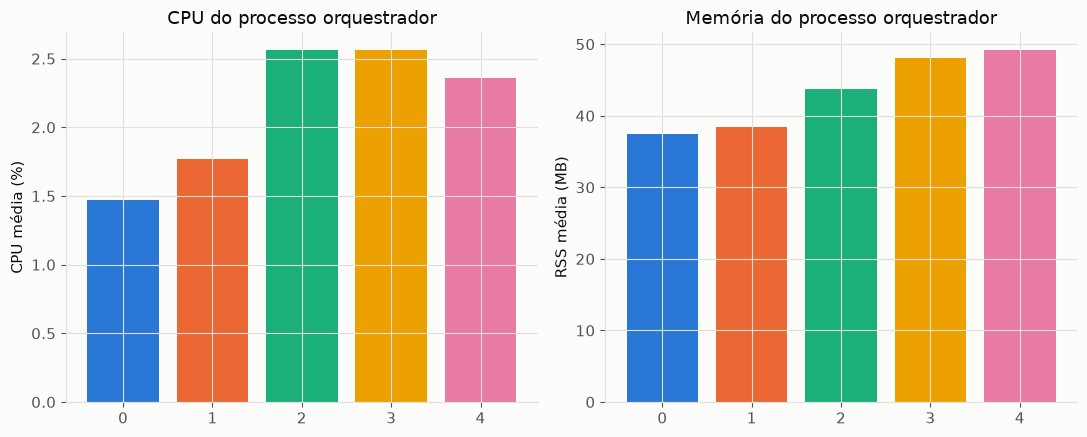

In [8]:
resource = subset(df, "resource_snapshot", ["scenario", "process", "cpu_percent", "rss_kb"]).dropna(subset=["cpu_percent"])
resource["cpu_percent"] = pd.to_numeric(resource["cpu_percent"])
resource["rss_kb"] = pd.to_numeric(resource["rss_kb"])

exp = resource[resource["process"] == "experiment"].groupby("scenario").agg(
    cpu_mean=("cpu_percent", "mean"), rss_mean_mb=("rss_kb", lambda s: s.mean() / 1024)
).reindex(scenarios)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].bar(range(len(scenarios)), exp["cpu_mean"], color=[SCENARIO_COLOR[s] for s in scenarios])
axes[0].set_ylabel("CPU média (%)")
axes[0].set_title("CPU do processo orquestrador", color=INK, fontsize=13)
axes[1].bar(range(len(scenarios)), exp["rss_mean_mb"], color=[SCENARIO_COLOR[s] for s in scenarios])
axes[1].set_ylabel("RSS média (MB)")
axes[1].set_title("Memória do processo orquestrador", color=INK, fontsize=13)
for ax in axes:
    ax.set_xticks(range(len(scenarios)))
    ax.set_xticklabels([SCENARIO_LABELS[s].split(" — ")[0] for s in scenarios])
fig.tight_layout()
fig.savefig("report/notebook_cpu_memoria.png", dpi=150)
plt.show()

## Rotação de chave vs. latência URLLC

Compara amostras de latência logo após uma confirmação de SA (`spi_confirmation_end`, conexão URLLC) contra o restante das amostras, nos cenários com rotação periódica.

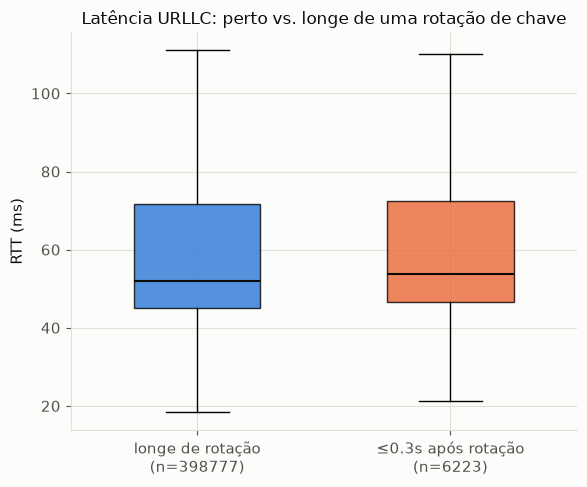

média longe: 57.10ms | média perto: 58.84ms (+3.0%)
p99 longe: 99.90ms | p99 perto: 105.00ms (+5.1%)


In [9]:
WINDOW_SECONDS = 0.3

rotations = subset(df, "spi_confirmation_end", ["scenario", "run_id", "ts", "connection"])
rotations = rotations[rotations["connection"] == "n3-urllc-cu-edge"]
lat_samples = subset(df, "latency_sample", ["scenario", "run_id", "ts", "label", "rtt_ms"])
lat_samples = lat_samples[lat_samples["label"] == "urllc"]

if not rotations.empty and not lat_samples.empty:
    near_mask = pd.Series(False, index=lat_samples.index)
    for run_id, rots in rotations.groupby("run_id")["ts"]:
        run_mask = lat_samples["run_id"] == run_id
        ts = lat_samples.loc[run_mask, "ts"].to_numpy()
        rots_arr = rots.to_numpy()
        is_near = np.zeros(len(ts), dtype=bool)
        for r in rots_arr:
            is_near |= (ts >= r) & (ts <= r + WINDOW_SECONDS)
        near_mask.loc[lat_samples.index[run_mask]] = is_near

    near = lat_samples.loc[near_mask, "rtt_ms"].astype(float)
    far = lat_samples.loc[~near_mask, "rtt_ms"].astype(float)

    fig, ax = plt.subplots(figsize=(6, 5))
    bp = ax.boxplot([far, near], patch_artist=True, showfliers=False, widths=0.5,
                     medianprops=dict(color=INK, linewidth=1.5))
    for patch, color in zip(bp["boxes"], ["#2a78d6", "#eb6834"]):
        patch.set_facecolor(color)
        patch.set_alpha(0.8)
    ax.set_xticks([1, 2])
    ax.set_xticklabels([f"longe de rotação\n(n={len(far)})", f"≤{WINDOW_SECONDS}s após rotação\n(n={len(near)})"])
    ax.set_ylabel("RTT (ms)")
    ax.set_title("Latência URLLC: perto vs. longe de uma rotação de chave", color=INK, fontsize=12)
    fig.tight_layout()
    fig.savefig("report/notebook_rotacao_vs_latencia.png", dpi=150)
    plt.show()

    print(f"média longe: {far.mean():.2f}ms | média perto: {near.mean():.2f}ms "
          f"({100*(near.mean()-far.mean())/far.mean():+.1f}%)")
    print(f"p99 longe: {far.quantile(0.99):.2f}ms | p99 perto: {near.quantile(0.99):.2f}ms "
          f"({100*(near.quantile(0.99)-far.quantile(0.99))/far.quantile(0.99):+.1f}%)")
else:
    print("sem rotações ou amostras de latência suficientes nesta coleta")